1. Сгенерируйте три случайные двумерные выборки для бинарной классификации 
(хотя бы по 400 точек в каждой) (Для генерации случайной выборки можно 
использовать функции из модуля sklearn.datasets): 
    a. с линейно разделимыми классами; 
    b. с хорошо разделимыми классами, но не линейно разделимыми; 
    c. с плохо разделимыми классами. 

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_blobs, make_circles, make_classification
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, classification_report
from sklearn.svm import SVC

# a) линейно разделимые
X1, y1 = make_blobs(
    n_samples=800,
    centers=2,
    cluster_std=1.2,
    random_state=42
)

# b) хорошо разделимые, но нелинейные
X2, y2 = make_circles(
    n_samples=800,
    noise=0.08,
    factor=0.45,
    random_state=42
)

# c) плохо разделимые
X3, y3 = make_classification(
    n_samples=800,
    n_features=2,
    n_redundant=0,
    n_informative=2,
    n_clusters_per_class=1,
    class_sep=0.5,
    flip_y=0.2,
    random_state=42
)

2. Визуализируйте полученные выборки на плоскости. 

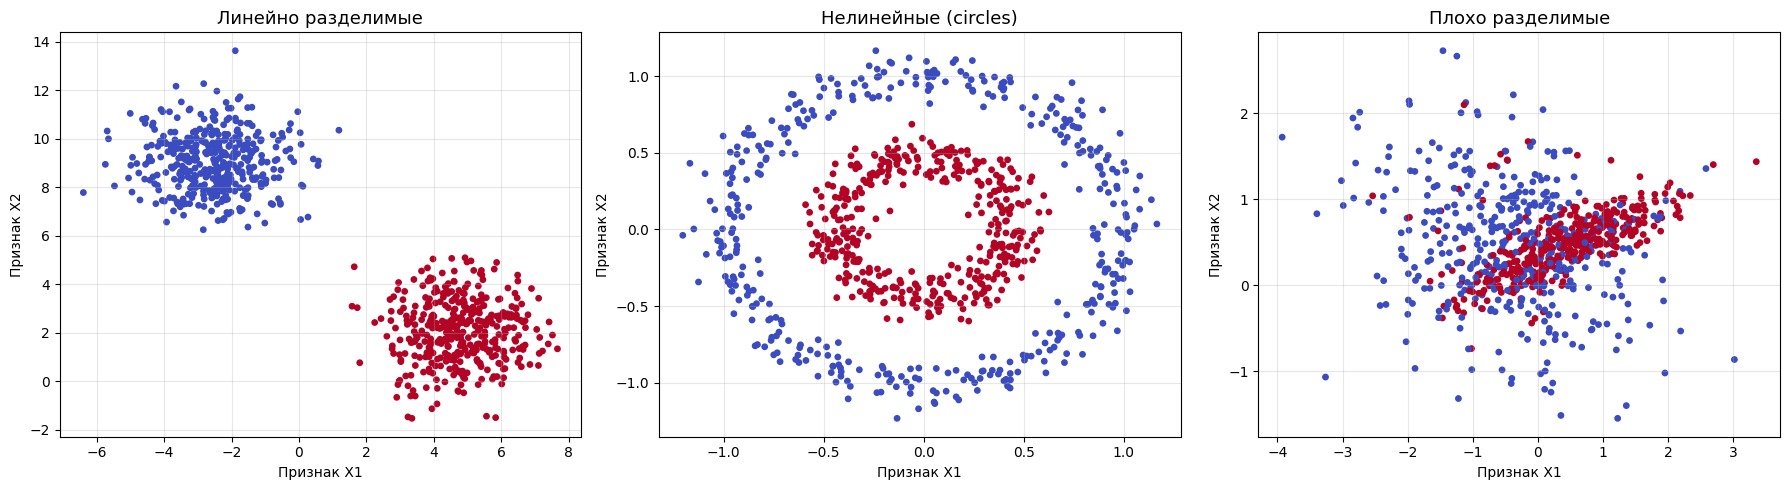

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

datasets = [
    (X1, y1, "Линейно разделимые"),
    (X2, y2, "Нелинейные (circles)"),
    (X3, y3, "Плохо разделимые")
]

for ax, (X, y, title) in zip(axes, datasets):
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', s=15)
    
    ax.set_title(title, fontsize=13)
    ax.set_xlabel("Признак X1")
    ax.set_ylabel("Признак X2")
    
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


3. Обучите на сгенерированных двумерных выборках ядровой SVM с 
использованием следующих типов ядер (для различных значений 
гиперпараметра C): 
    a. линейное: K(x,z)=⟨x,z⟩; 
    b. полиномиальное: K(x,z)=(γ⟨x,z⟩+1)d (для различных значений γ,d); 
    c. гауссовское: K(x,z)=exp(−γ∥x−z∥2) (для различных значений γ). 

In [13]:
# визуализация границы SVM
def plot_svm(model, X, y, title):
    x_min, x_max = X[:,0].min()-1, X[:,0].max()+1
    y_min, y_max = X[:,1].min()-1, X[:,1].max()+1

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 400),
        np.linspace(y_min, y_max, 400)
    )

    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    plt.figure(figsize=(7,6))
    plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
    plt.scatter(X[:,0], X[:,1], c=y, cmap='coolwarm', s=20)
    plt.title(title)
    plt.show()

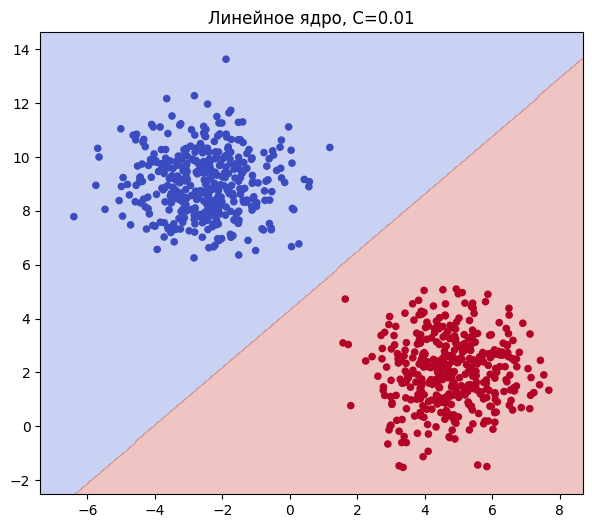

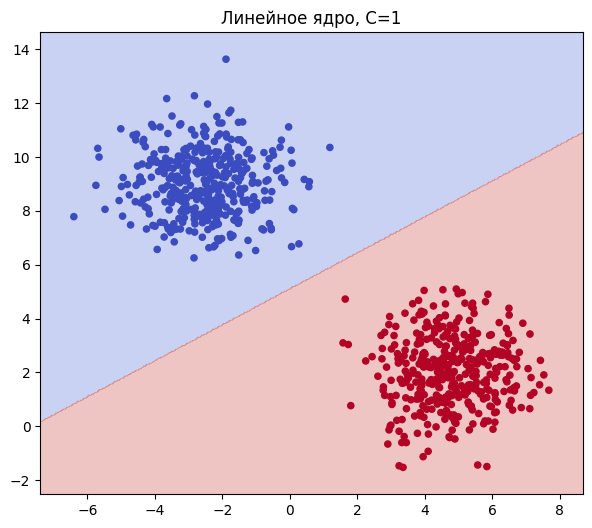

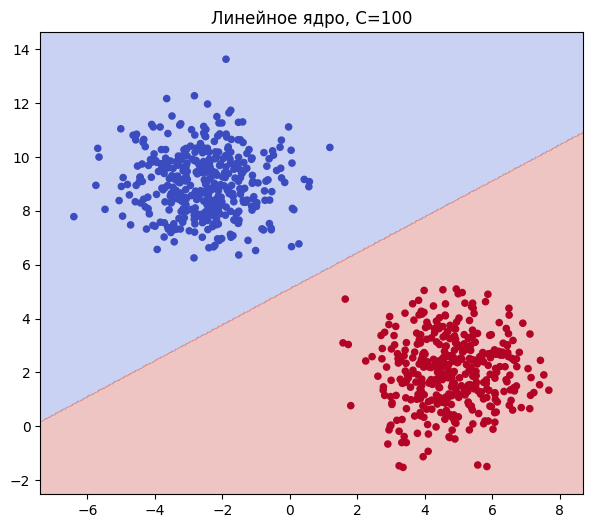

In [14]:
for C in [0.01, 1, 100]:
    model = SVC(kernel='linear', C=C)
    model.fit(X1, y1)
    plot_svm(model, X1, y1, f"Линейное ядро, C={C}")

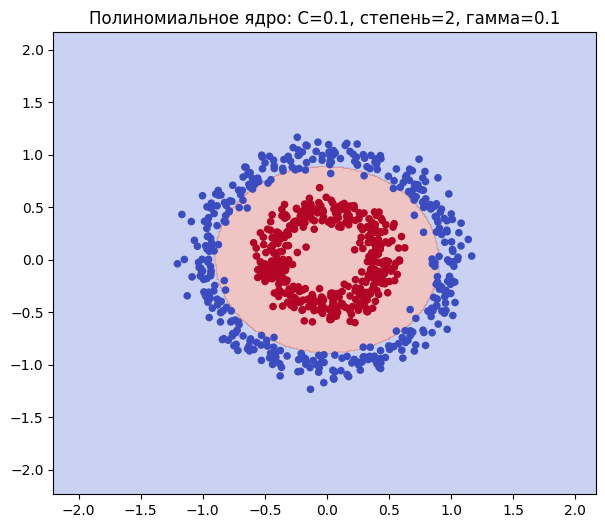

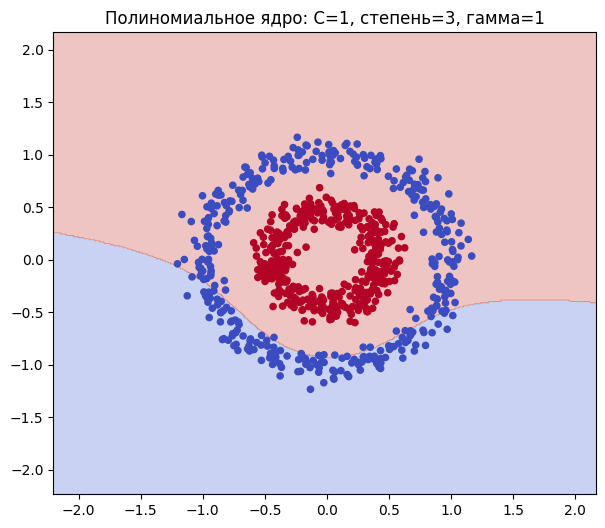

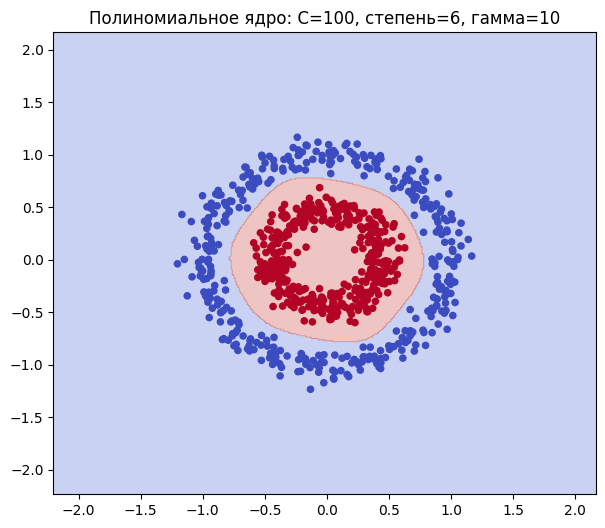

In [15]:
params_poly = [
    (0.1, 2, 0.1),   # недообучение
    (1, 3, 1),       # норма
    (100, 6, 10)     # переобучение
]

for C, d, gamma in params_poly:
    model = SVC(kernel='poly', C=C, degree=d, gamma=gamma)
    model.fit(X2, y2)
    plot_svm(model, X2, y2,
             f"Полиномиальное ядро: C={C}, степень={d}, гамма={gamma}")


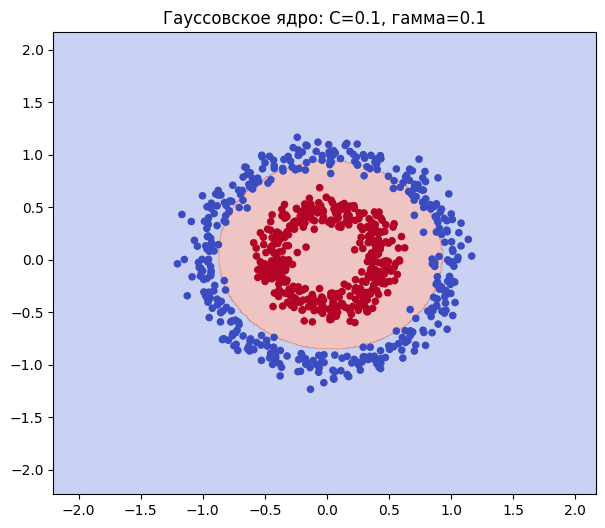

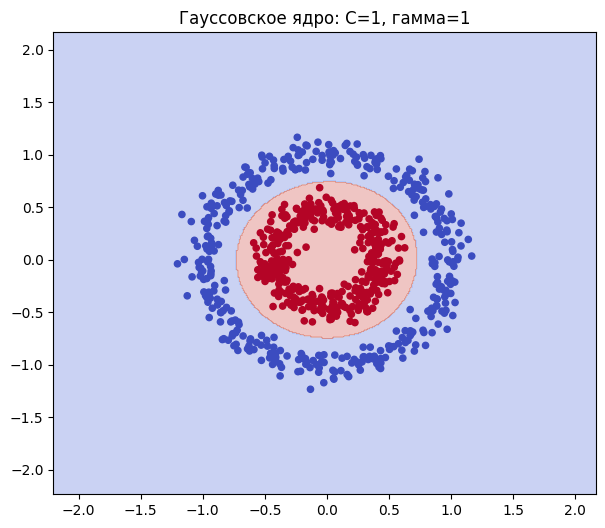

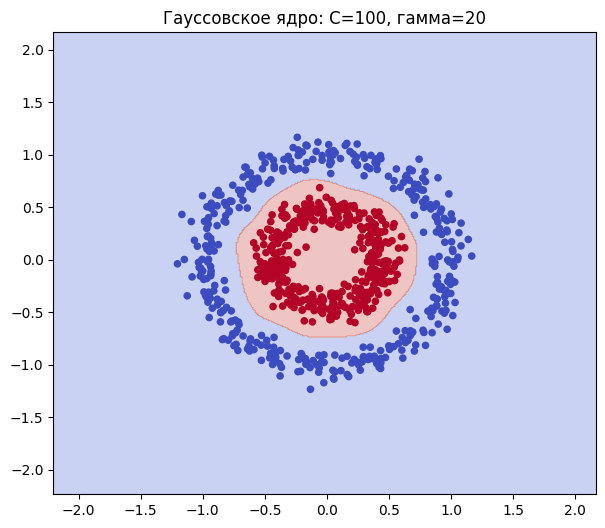

In [16]:
params_rbf = [
    (0.1, 0.1),   # недообучение
    (1, 1),       # норма
    (100, 20)     # переобучение
]

for C, gamma in params_rbf:
    model = SVC(kernel='rbf', C=C, gamma=gamma)
    model.fit(X2, y2)
    plot_svm(model, X2, y2,
             f"Гауссовское ядро: C={C}, гамма={gamma}")

5. Как ведет себя SVM с полиномиальным ядром в зависимости от значений 
гиперпараметра C, степени ядра d и параметра γ? 

Влияние C:
Малый C: мягкая граница, допускает ошибки, недообучение
Большой C: старается всё разделить идеально, сложная граница, переобучение
Влияние степени ядра:
Малый d (2): почти линейная граница
Средний d (3–5) : Хорошая нелинейность
Большой d (8+): очень извилистая граница, переобучение, влияние гамма, контролирует вклад скалярного произведения.
Гамма:
Малый гамма: граница плавная.
Большой гамма: резкие перегибы, часто переобучение

6. Как ведет себя SVM с гауссовским ядром в зависимости от значений 
гиперпараметра C и γ? 

Влияние гамма:
Маленький гамма: каждая точка влияет далеко, граница гладкая -> недообучение
Большой гамма: каждая точка влияет локально, граница извилистая -> переобучение

Влияние C:
Малый C: допускает ошибки
Большой C: подгоняет train

Идеальная зона:
C = 1..10
gamma = 0.01..0.1

7. Обучите модели с использованием ядер из п. 2 для задачи бинарной 
классификации Predicting a Biological Response (используйте файл train.csv) для 
значения C=1. Для оценки качества разбейте выборку на обучающую и тестовую 
в отношении 50/50. Постройте модель, позволяющую достичь значения accuracy, 
равного 0.75, на тестовой выборке. Позволяет ли использование ядер достичь 
лучшего качества по сравнению с линейной моделью? 

In [10]:
df = pd.read_csv("predicting_train.csv")

print(df.head())
print(df.shape)

# целевая переменная
target = "Activity"

X = df.drop(columns=[target])
y = df[target]

# категориальные и числовые признаки
cat_cols = X.select_dtypes(include=["object"]).columns.tolist()
num_cols = X.select_dtypes(exclude=["object"]).columns.tolist()

# preprocessing
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
])

# train/test 50/50
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.5,
    random_state=42,
    stratify=y
)

# Модели

models = {
    "Linear": SVC(kernel='linear', C=1),
    "Poly": SVC(kernel='poly', C=1, degree=3, gamma='scale'),
    "RBF": SVC(kernel='rbf', C=1, gamma='scale')
}

results = {}

for name, clf in models.items():
    pipe = Pipeline([
        ("prep", preprocessor),
        ("model", clf)
    ])

    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)

    acc = accuracy_score(y_test, pred)
    results[name] = acc
    print(f"{name}: accuracy = {acc:.4f}")

# улучшенная модель (0.75+)

pipe_best = Pipeline([
    ("prep", preprocessor),
    ("pca", PCA()),
    ("model", SVC(kernel="rbf"))
])

param_grid = {
    "pca__n_components": [100, 200, 300],
    "model__C": [1, 3, 10],
    "model__gamma": [0.001, 0.005, 0.01, 0.05]
}

grid = GridSearchCV(
    estimator=pipe_best,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1
)

print("\nИДЕТ ПОДБОР ПАРАМЕТРОВ...\n")

grid.fit(X_train, y_train)


# лучшая модель

print("\nЛучшие параметры:")
print(grid.best_params_)

print("\nЛучший CV score:")
print(round(grid.best_score_, 4))

best_model = grid.best_estimator_

pred = best_model.predict(X_test)

acc = accuracy_score(y_test, pred)

print("\nТест точности =", round(acc, 4))

print("\nClassification report:\n")
print(classification_report(y_test, pred))


   Activity        D1        D2    D3   D4        D5        D6        D7  \
0         1  0.000000  0.497009  0.10  0.0  0.132956  0.678031  0.273166   
1         1  0.366667  0.606291  0.05  0.0  0.111209  0.803455  0.106105   
2         1  0.033300  0.480124  0.00  0.0  0.209791  0.610350  0.356453   
3         1  0.000000  0.538825  0.00  0.5  0.196344  0.724230  0.235606   
4         0  0.100000  0.517794  0.00  0.0  0.494734  0.781422  0.154361   

         D8        D9  ...  D1767  D1768  D1769  D1770  D1771  D1772  D1773  \
0  0.585445  0.743663  ...      0      0      0      0      0      0      0   
1  0.411754  0.836582  ...      1      1      1      1      0      1      0   
2  0.517720  0.679051  ...      0      0      0      0      0      0      0   
3  0.288764  0.805110  ...      0      0      0      0      0      0      0   
4  0.303809  0.812646  ...      0      0      0      0      0      0      0   

   D1774  D1775  D1776  
0      0      0      0  
1      0      1   

Получены результаты точности на тестовой выборке:

Linear kernel - 0.6914
Polynomial kernel - 0.5853
RBF kernel (без подбора гиперпараметров) - ниже линейной модели
RBF kernel после подбора параметров и PCA - 0.78

Наилучший результат показала гауссовская модель (RBF kernel) после настройки гиперпараметров.

Это означает, что в данных присутствуют нелинейные зависимости между признаками и целевой переменной, которые линейная модель не способна полностью уловить.

Использование метода главных компонент (PCA) позволило уменьшить размерность пространства признаков, снизить шум и улучшить обобщающую способность модели.

Полиномиальное ядро показало худший результат, так как:

при высокой размерности признаков полиномиальное отображение становится слишком сложным
возрастает риск переобучения
модель чувствительна к выбору степени полинома и параметра gamma